# Multi-label classification — quickstart

**Multi-label classification** tags an image with *any number* of labels — none, one, or several — instead of forcing one. Photo tagging, defect types that co-occur, and medical findings are all multi-label. Each label is its own yes/no question.

This notebook runs the **whole pipeline in about ten cells**. The other notebooks slow down and explain each step.

**Data → Train → Evaluate → Predict** &nbsp;·&nbsp; runs on CPU in about 1 minutes with the `quick` preset.

In [1]:
# Run this cell first.
# On Colab it clones the kit and installs what's missing; locally it just finds the repo root.
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules and not Path("cvkit").exists():
    subprocess.run(["git", "clone", "-q", "https://github.com/standungan/computer-vision-starter-kit"], check=True)
    os.chdir("computer-vision-starter-kit")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyyaml", "scikit-learn", "gradio"], check=True)
while not Path("cvkit").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)          # notebooks live 3 folders below the repo root
sys.path.insert(0, os.getcwd())
print("working in", Path.cwd().name)

working in computer-vision-starter-kit


In [2]:
%config InlineBackend.figure_format = "jpeg"
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 90}}   # keeps saved notebooks small

from PIL import Image

from cvkit.config import load_config
from cvkit.synthetic import make_demo_data
from cvkit.utils import seed_everything

# quick.yaml = small synthetic demo, runs on a laptop CPU in minutes.
# Swap in default.yaml (bigger, pretrained) or your own config + data when you're ready.
CONFIG = "tasks/multilabel/configs/quick.yaml"
cfg = load_config(CONFIG)
seed_everything(cfg["seed"])

if not Path(cfg["data"]["root"]).exists():          # first run: create the demo dataset
    make_demo_data("multilabel", cfg)
print("task:", "multilabel", "| data:", cfg["data"]["root"], "| outputs:", cfg["output"]["dir"])

task: multilabel | data: data/demo/multilabel | outputs: outputs/multilabel_quick


## 1 · The data
A few examples, with their labels:

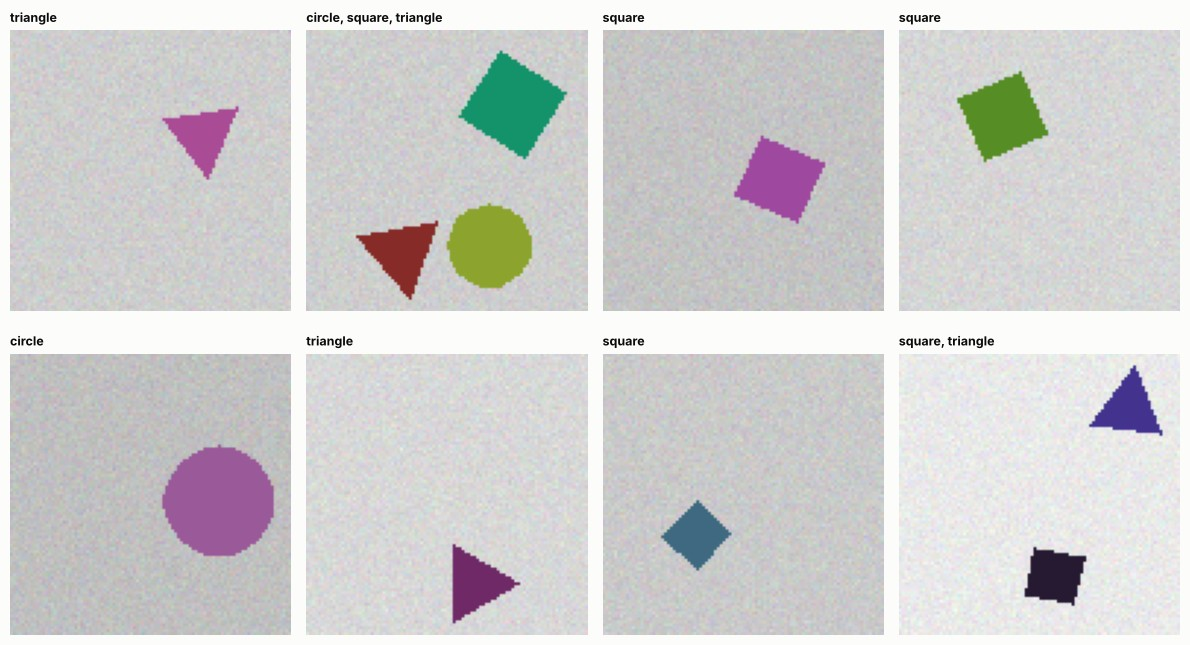

In [3]:
from PIL import Image
from cvkit.viz import image_grid
from tasks.multilabel.data import build_datasets

ds = build_datasets(cfg)
classes, samples = ds["classes"], ds["samples"]
picks = samples[:8]
_ = image_grid([Image.open(p) for p, _ in picks],
               [", ".join(c for c, v in zip(classes, t) if v) or "(none)" for _, t in picks], cols=4)

## 2 · Train
`train(cfg)` is the same function the command line calls: `python -m cvkit multilabel train --quick`. It prints one line per epoch and saves the best model.

In [4]:
from tasks.multilabel.train import train

result = train(cfg)

arch: resnet18 | labels (3): ['circle', 'square', 'triangle']
device: cpu | parameters: 11,178,051 total, 11,178,051 trainable (100.0%)


epoch   1/15 | train_loss 0.7370 | val loss=3.158 f1_macro=0.495 f1_micro=0.611 map=0.732 exact=0.162 | 3.1s  <- best


epoch   2/15 | train_loss 0.5980 | val loss=0.799 f1_macro=0.525 f1_micro=0.560 map=0.879 exact=0.250 | 2.9s  <- best


epoch   3/15 | train_loss 0.5516 | val loss=0.652 f1_macro=0.557 f1_micro=0.587 map=0.880 exact=0.250 | 2.9s  <- best


epoch   4/15 | train_loss 0.5025 | val loss=0.830 f1_macro=0.590 f1_micro=0.642 map=0.832 exact=0.309 | 4.0s


...

epoch  11/15 | train_loss 0.1598 | val loss=0.260 f1_macro=0.885 f1_micro=0.886 map=0.972 exact=0.676 | 3.0s  <- best


epoch  12/15 | train_loss 0.0940 | val loss=0.074 f1_macro=0.978 f1_micro=0.978 map=1.000 exact=0.926 | 2.8s  <- best


epoch  13/15 | train_loss 0.0650 | val loss=0.041 f1_macro=0.992 f1_micro=0.991 map=1.000 exact=0.971 | 3.0s  <- best


epoch  14/15 | train_loss 0.0435 | val loss=0.027 f1_macro=0.996 f1_micro=0.996 map=1.000 exact=0.985 | 2.9s


epoch  15/15 | train_loss 0.0333 | val loss=0.028 f1_macro=0.996 f1_micro=0.996 map=1.000 exact=0.985 | 2.9s
best val map = 1.0000 (epoch 13) -> outputs/multilabel_quick/checkpoints/best.pt


## 3 · Evaluate on the held-out test split
Images the model never trained on, and never used to pick its best epoch.

In [5]:
from tasks.multilabel.evaluate import evaluate

metrics = evaluate(cfg)

threshold 0.5: mAP 1.0000 | macro-F1 0.9956 | micro-F1 0.9951 | exact-match 0.9853
              precision    recall  f1-score   support

      circle      1.000     1.000     1.000        31
      square      0.974     1.000     0.987        37
    triangle      1.000     1.000     1.000        34

   micro avg      0.990     1.000     0.995       102
   macro avg      0.991     1.000     0.996       102
weighted avg      0.990     1.000     0.995       102
 samples avg      0.993     1.000     0.995       102

reports -> outputs/multilabel_quick/reports


per_label_metrics.png


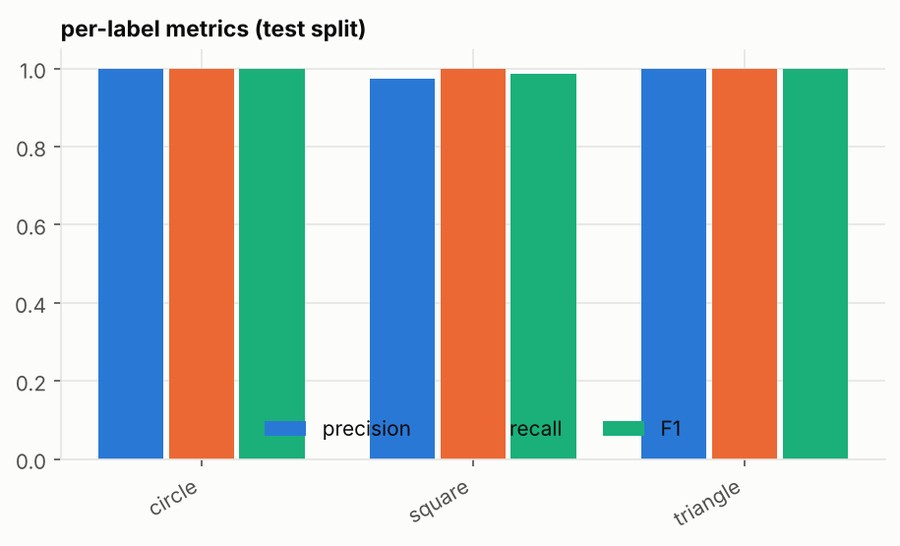

threshold_sweep.png


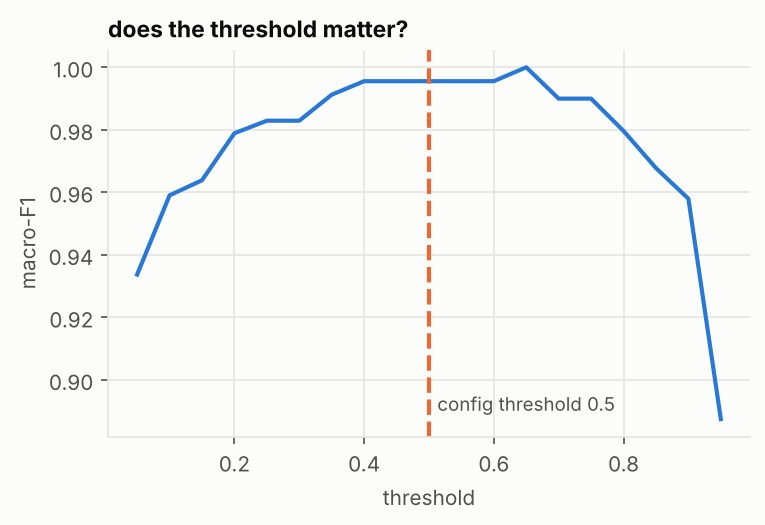

worst_images.png


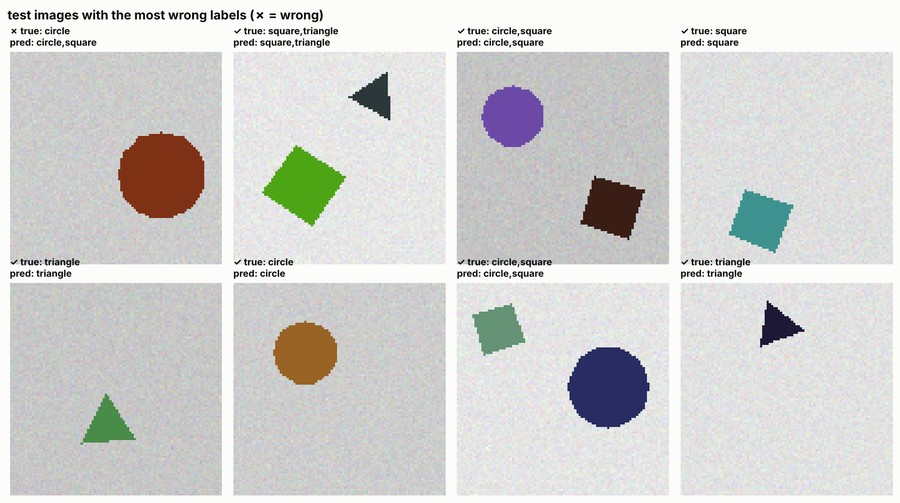

In [6]:
from cvkit.viz import show_image

reports = Path(cfg["output"]["dir"]) / "reports"
for name in ['per_label_metrics.png', 'threshold_sweep.png', 'worst_images.png']:
    print(name)
    show_image(reports / name)

**Reading it:** `per_label_metrics.png` shows precision, recall and F1 for each label — a weak label stands out. `threshold_sweep.png` shows macro-F1 as the yes/no cut-off moves, so you can see whether 0.5 was a good choice.

## 4 · Predict
`Predictor.predict` returns *every* label with its probability and whether it clears the threshold:

In [7]:
from tasks.multilabel.predict import Predictor
from tasks.multilabel.data import test_image_paths

predictor = Predictor.from_config(cfg)
for path in test_image_paths(cfg, 4):
    preds = predictor.predict(path)
    present = [f"{r['label']} {r['confidence']:.2f}" for r in preds if r["present"]]
    print(Path(path).name, "->", ", ".join(present) or "(nothing above threshold)")

img_0155.png -> triangle 1.00, square 0.98
img_0184.png -> circle 1.00, square 0.92
img_0044.png -> square 0.96
img_0112.png -> triangle 1.00


## What next?
* **[01_data](01_data.ipynb)** — look at the data and augmentation properly
* **[02_train_and_evaluate](02_train_and_evaluate.ipynb)** — learning curves, how to read the metrics, experiments
* **[03_predict_and_deploy](03_predict_and_deploy.ipynb)** — your own images, the demo app, deployment
* Read the task's [README](../README.md) · use your own data: [data formats](../../../docs/data-formats.md)